# F1 60% 이상 + 기존 오탐 수 상한 유지

**기존 로그 전체 평가에서는 IF·K-means·LOF 모두 달성. ADBench 공식 생성기 기반 1,000개도 별도 정상 학습 방식으로 달성. 서비스 모델을 그대로 적용하는 무학습 전이는 여전히 미달이다.**

두 학습 프로토콜과 모델 파일은 서로 다르다. 데이터/정답/난이도를 변경하거나 Hard·어려운 시점을 빼지 않았다.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]if(p/'reports/shared_model_v4_final/summary.json').exists())
LOG=ROOT/'reports/shared_model_v4_final'; AD=ROOT/'reports/shared_model_v4_adbench_release'
read=lambda p:json.loads(p.read_text(encoding='utf-8'))
old=read(ROOT/'reports/shared_model_v3_release/summary.json'); new=read(LOG/'summary.json'); ad=read(AD/'results.json')
alg=['if','kmeans','lof']
def metrics(rows):
    return (pd.DataFrame(rows).set_index('method')[['accuracy','precision','recall','f1','normal_false_positive_rate']]*100).round(2)

## 1. 기존 로그: 전체 성능과 오탐 수

같은 **2,167,766개 1분 판정**: 정상 1,785,918 / 이상 381,848. 오탐률은 FP/(TN+FP). 이상 사례 속 정상 배경과 별도 정상 대조군을 모두 포함한다. 경보는 **점수 > 경보선**, point adjustment 없음. 아래의 전체 F1이 모든 시나리오의 F1을 보장하지 않는다.

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,89.67,81.90,53.06,64.40,2.51
kmeans,91.54,88.30,59.88,71.36,1.70
lof,90.94,88.31,56.00,68.53,1.59


,모델,이전 F1,현재 F1,F1 증가 %p,이전 FP 상한,현재 FP,F1 60% 이상,오탐 상한 유지
0,if,56.79,64.40,7.60,53829,44773,True,True
1,kmeans,58.93,71.36,12.43,36546,30282,True,True
2,lof,55.06,68.53,13.48,42848,28312,True,True


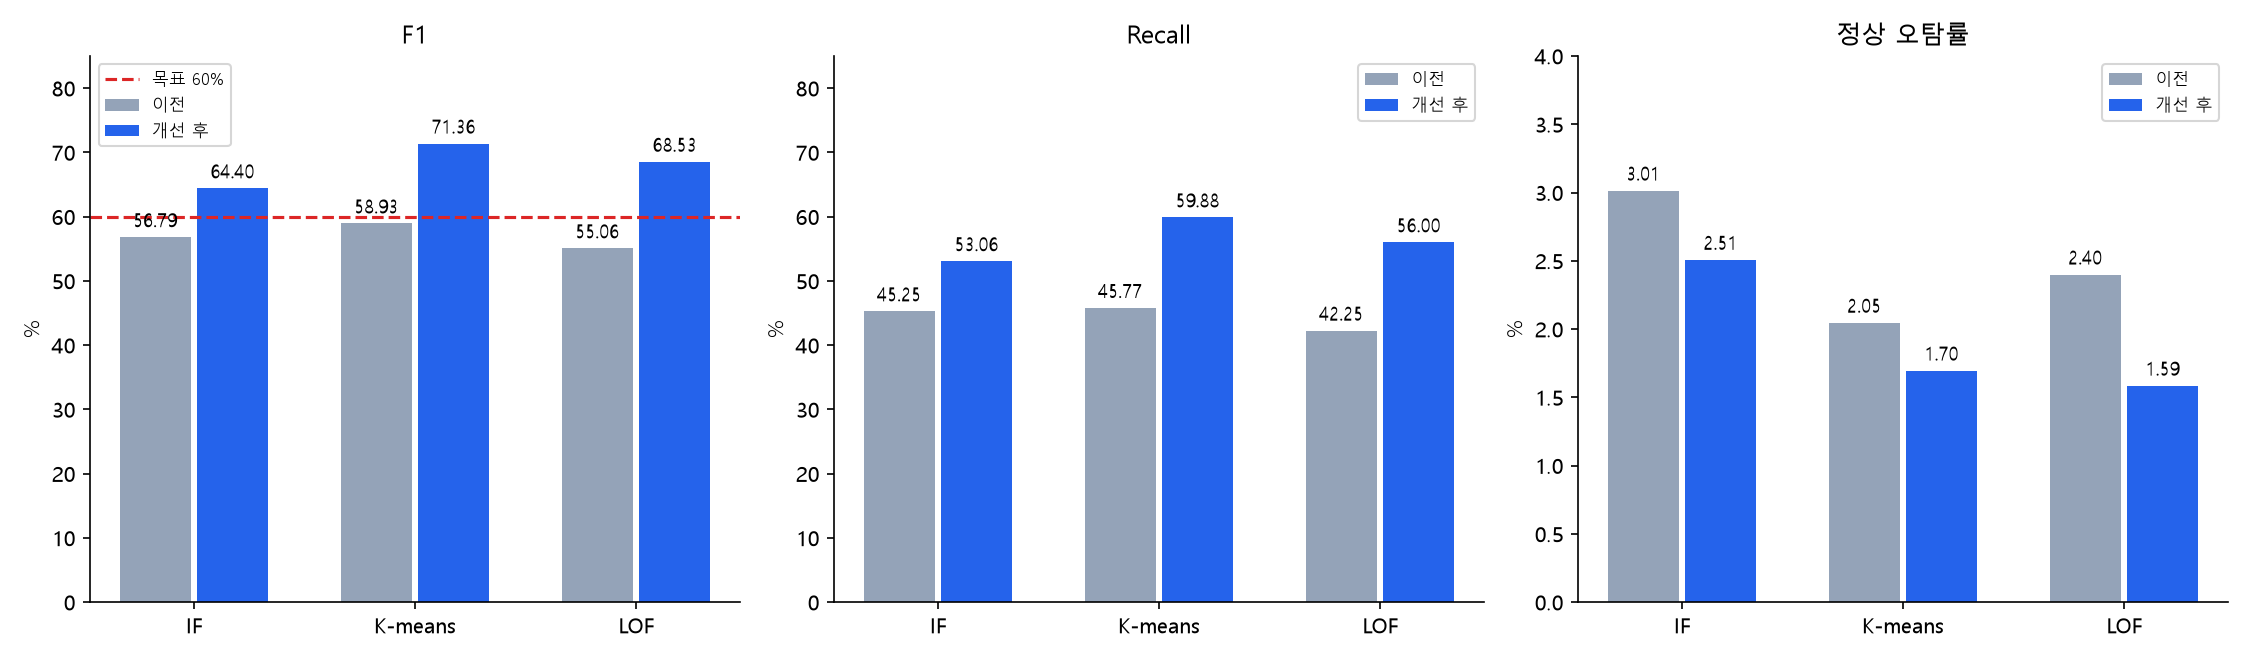

In [2]:
display(metrics(new['pooled']))
compare=[]
for b,r in zip(old['pooled'],new['pooled']):
    compare.append({'모델':r['method'],'이전 F1':round(b['f1']*100,2),'현재 F1':round(r['f1']*100,2),'F1 증가 %p':round((r['f1']-b['f1'])*100,2),'이전 FP 상한':b['fp'],'현재 FP':r['fp'],'F1 60% 이상':r['F1_target_met'],'오탐 상한 유지':r['FP_cap_met']})
display(pd.DataFrame(compare)); display(Image(filename=str(LOG/'figures/log_comparison.png')))

## 2. 무엇을 바꿨나

- **연속 지연**: 같은 Adapter+Process 스트림에서 첫 최대 6개 완료 관측의 소요시간 최댓값보다 현재 값이 연속해서 큰 정도. 소요시간 중앙값만 보면 가려질 수 있는 개별 실행을 위해 1분 최댓값 사용. 초기 관측이 정상이라는 보증은 없으며 오염되면 민감도가 떨어질 수 있다.
- **지연 변화·짧은 기억**: 현재 소요시간의 초기 관측 내 순위, 중앙값 대비 증가, 과거 값만 누적한 CUSUM 유사 피처. 완료 로그가 없을 때 최근 증거를 최대 8분만 감쇠 보관하고 새 정상 관측에서 해제. 이것은 새 하드 룰이 아니라 모델 입력 피처. 순위 점수를 엄밀한 p-value라고 해석하지 않는다.
- **트래픽**: 정상 참조 이력의 평일/주말·시간대별 요청 수 분포로 현재/최근 3·5분 요청 수의 드문 정도 및 무입력 지속을 계산. 요청 수는 실행 횟수이고 `totalCount`(실행 1건의 처리 건수)와 다르다. 이 참조 이력은 합성 prior로 실제 운영에서는 운영 이력으로 재구축해야 한다.
- **한 개의 탐지기**: 알고리즘별 전체 단일 모델 유지, Adapter 전문가 모델 없음. IF·LOF는 기존 Adapter 파생 수치 9개도 사용. K-means는 개발 검증에서 더 나았던 19개 간결 피처를 선택했으므로 Adapter 9개를 직접 입력하지는 않는다. 조건부 `current_source_upper/lower`에는 기존 집단 참조가 간접 반영된다.

In [3]:
selection=read(LOG/'selection.json'); manifest=read(LOG/'handoff/manifest.json')
for r in manifest['models']:
    display(Markdown('### '+r['algorithm']))
    display(pd.Series({'입력 피처 수':len(r['columns']),'학습 행':r['fit_rows'],'경보선':r['threshold'],'보정 방식':r['calibration_mode']+' / '+r['calibration_kind'],'실제 추정기 설정':r['actual_estimator_parameters'],'경보 정책':selection['models'][r['algorithm']]['threshold_policy']},name='실제 설정').to_frame())
    display(pd.Series(r['columns'],name='입력 피처').to_frame())

### if

,실제 설정
입력 피처 수,28
학습 행,19793
경보선,1.536478
보정 방식,availability / robust
실제 추정기 설정,"{'bootstrap': False, 'contamination': 'auto', ..."
경보 정책,normal calibration P99.25


,입력 피처
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_upper
6,current_source_lower
7,adapter_max_duration_z
8,adapter_p95_upper_tail
9,adapter_count_p95_z


### kmeans

,실제 설정
입력 피처 수,19
학습 행,19793
경보선,5.854851
보정 방식,availability / cdf
실제 추정기 설정,"{'batch_size': 2048, 'compute_labels': True, '..."
경보 정책,unchanged development-selected normal calibrat...


,입력 피처
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_upper
6,current_source_lower
7,rank_upper_run
8,rank_lower_run
9,rank_upper_memory


### lof

,실제 설정
입력 피처 수,28
학습 행,4096
경보선,2.178462
보정 방식,availability / robust
실제 추정기 설정,"{'algorithm': 'auto', 'contamination': 'auto',..."
경보 정책,normal calibration P99.5


,입력 피처
0,current_arrival_excess
1,current_prefix_burst
2,gap_expected_prefix
3,gap_expected_recent
4,empty_expected_rate
5,current_source_upper
6,current_source_lower
7,adapter_max_duration_z
8,adapter_p95_upper_tail
9,adapter_count_p95_z


## 3. 경보 기준을 어떻게 정했나

탐지기 학습은 기존 정상 후보 **19,793개 분 집계**, 별도 정상 calibration **17,925개**로 점수 보정. 개발용 search/confirmation 라벨은 피처·하이퍼파라미터 선택에 사용했다. S 상태는 성능 정상의 절대 보증이 아니다.

최초 rank 피처 후보는 전체 F1 70% 이상이었으나 IF·LOF 오탐 상한 초과로 탈락. IF·LOF를 정상 calibration P99.5로 보수화하니 IF F1 59.51%로 미달. 최종 IF **정상 calibration P99.25**, LOF **P99.5**, K-means는 개발 선택 기준 유지. 각 시도는 평가 전에 cutoff를 고정했고 평가 점수의 ROC/정답 quantile에서 cutoff를 역산하지 않았다. **다만 이전 전체 평가 결과를 보고 정책을 재설계한 반복 실험이므로, 이 평가셋을 블라인드 테스트라고 주장할 수 없다.** P99.25라는 값이 새 환경 오탐률을 보장하지 않는다.

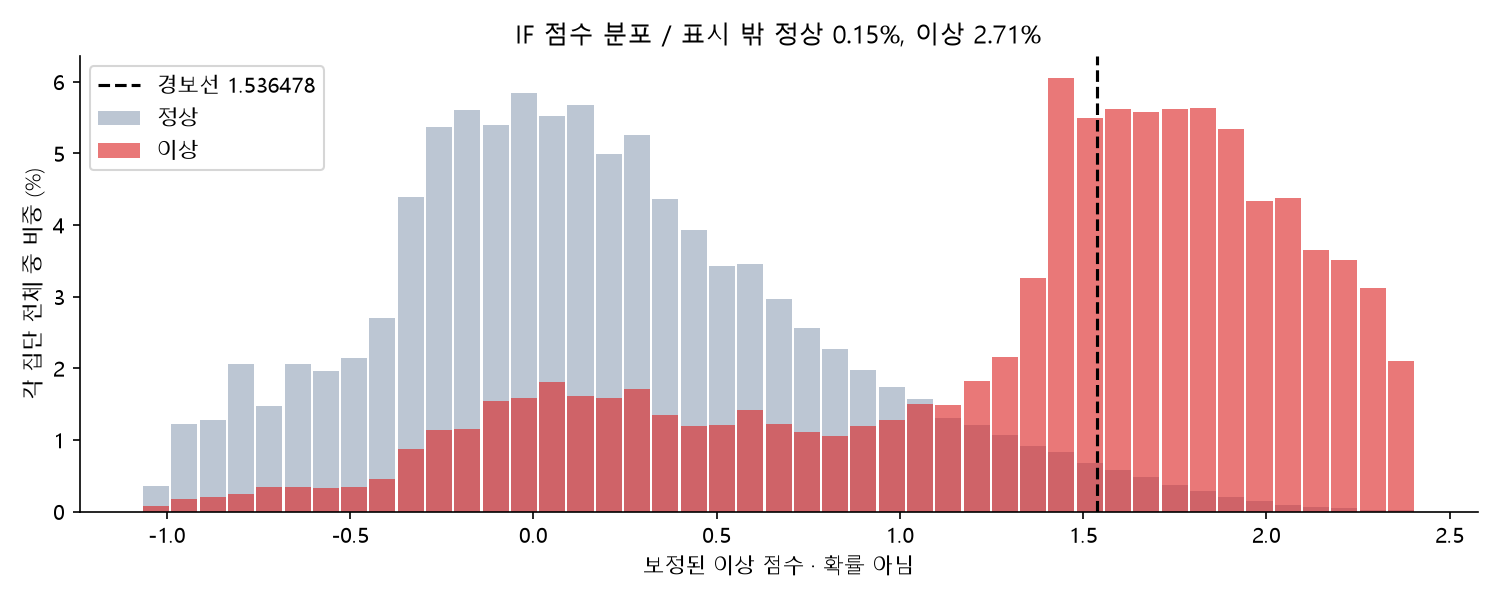

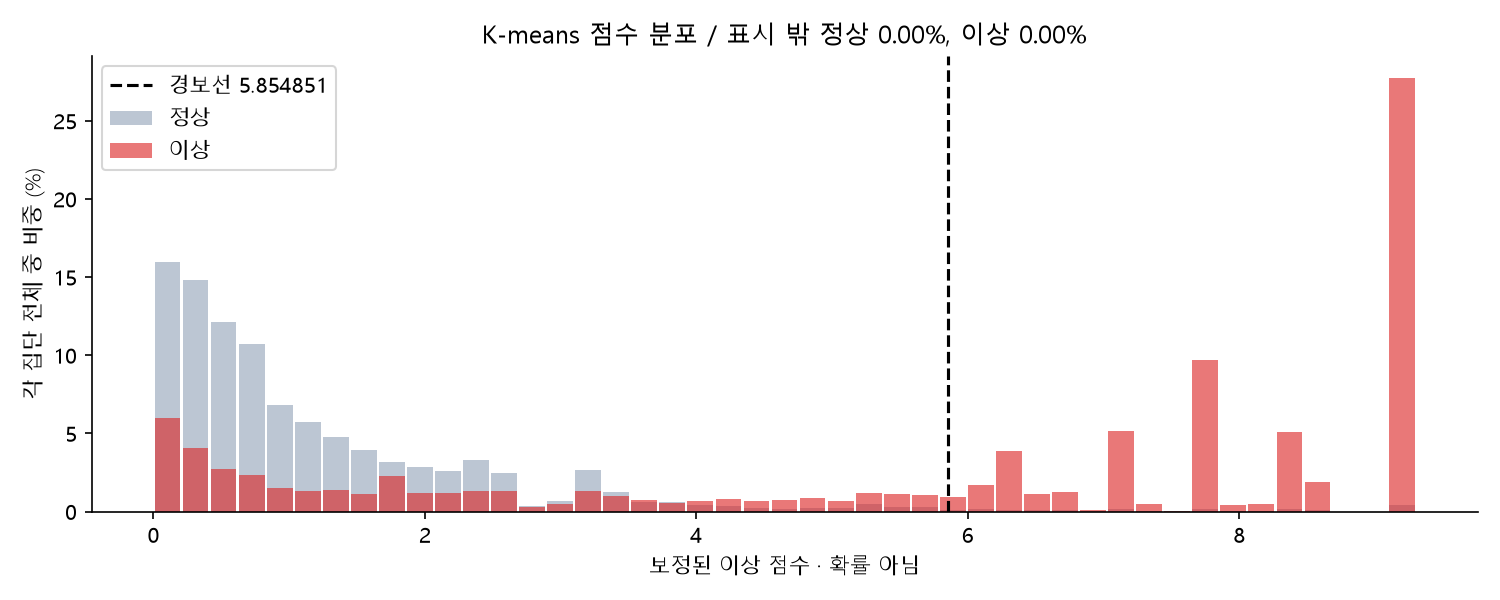

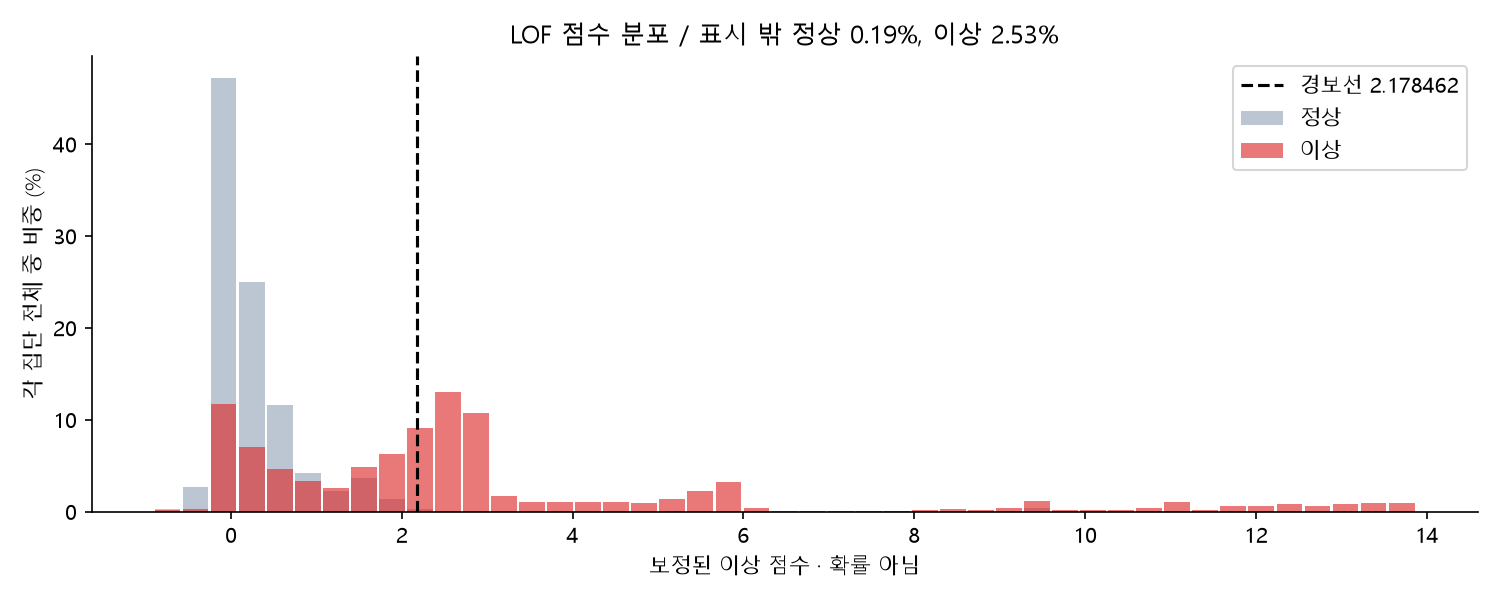

In [4]:
for a in alg:display(Image(filename=str(LOG/'figures'/f'{a}_threshold.png')))

## 4. 시나리오별 강점·실패를 반드시 같이 보기

전체 F1은 이상 분 수가 많은 시나리오의 영향을 크게 받는다. 아래 macro F1은 7개 시나리오 F1의 단순 평균으로 전체 F1과 다르다. 특히 **현재 IF는 기존 개별 지연·컬럼 관계에서 TP=0**, LOF는 시간대 폭주에서 약하다. 전체 목표 달성을 개별 이상 유형의 해결로 포장하면 안 된다.

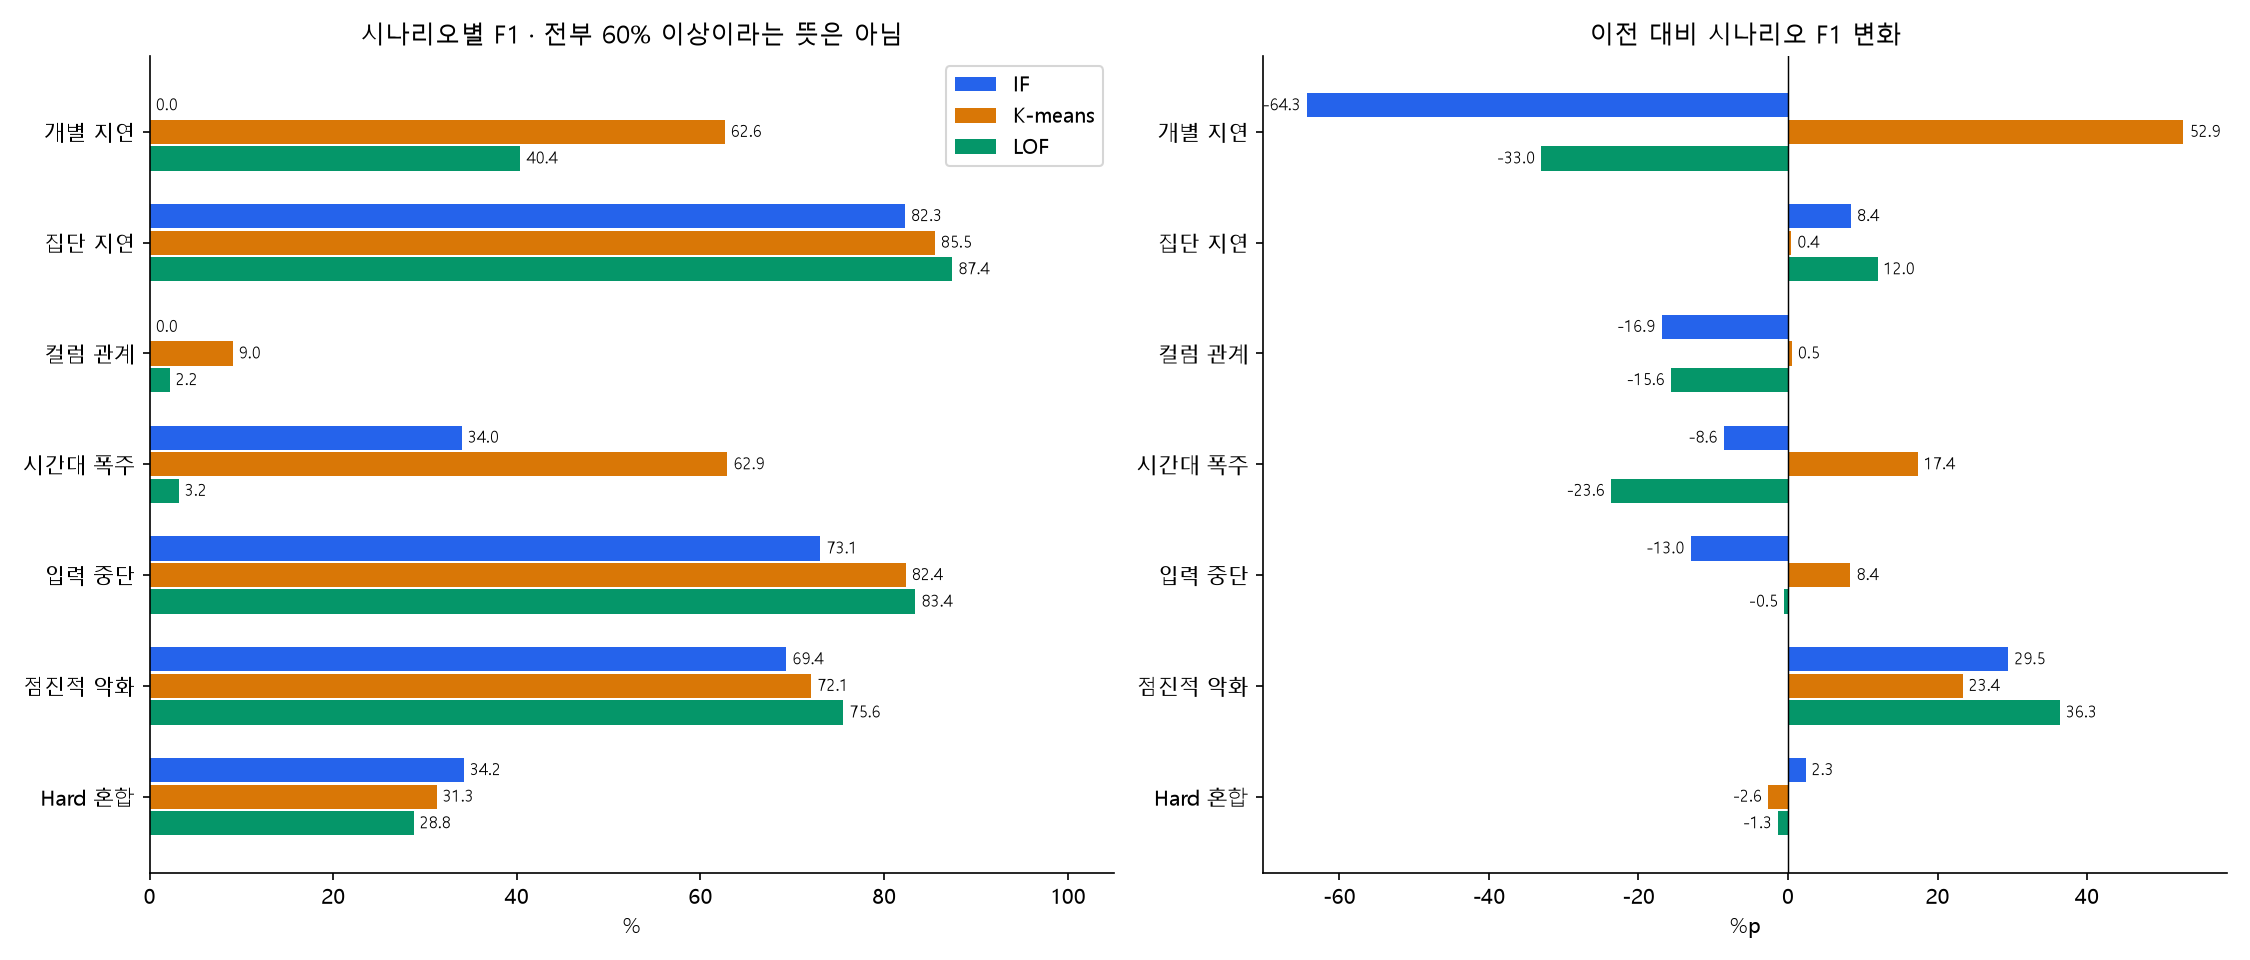

,시나리오,모델,정상 분,이상 분,TP,FP,F1 %,Recall %,오탐률 %
0,individual_delay,if,54891,5093,0,478,0.00,0.00,0.87
1,individual_delay,kmeans,54891,5093,2366,96,62.63,46.46,0.17
2,individual_delay,lof,54891,5093,1301,48,40.39,25.54,0.09
3,group_delay,if,308714,55116,46666,11668,82.27,84.67,3.78
4,group_delay,kmeans,308714,55116,47743,8808,85.51,86.62,2.85
5,group_delay,lof,308714,55116,47549,6107,87.43,86.27,1.98
6,column_relation,if,50000,10000,0,302,0.00,0.00,0.60
7,column_relation,kmeans,50000,10000,473,0,9.03,4.73,0.00
8,column_relation,lof,50000,10000,110,0,2.18,1.10,0.00
9,time_burst,if,357193,41663,9152,3028,34.00,21.97,0.85


,시나리오 macro F1 %
모델,
if,41.84
kmeans,57.97
lof,45.84


In [5]:
display(Image(filename=str(LOG/'figures/scenario_comparison.png')))
rows=[]
for d in new['datasets']:
    for r in d['metrics']:rows.append({'시나리오':d['dataset'],'모델':r['method'],'정상 분':r['normal'],'이상 분':r['anomaly'],'TP':r['tp'],'FP':r['fp'],'F1 %':round(r['f1']*100,2),'Recall %':round(r['recall']*100,2),'오탐률 %':round(r['normal_false_positive_rate']*100,2)})
table=pd.DataFrame(rows); display(table); display(table.groupby('모델')['F1 %'].mean().round(2).rename('시나리오 macro F1 %').to_frame())

## 5. ADBench: 별도 정상 학습한 결과

기존 **1,000개(정상 800 / 이상 200)**는 변경하지 않았다. ADBench 0.1.11 공식 생성기 global/local/cluster/dependency를 사용한 기존 피처 표이며, ADBench 전체 공개 실제 데이터셋의 종합 성능이 아니다. 시간축·원시 Process 이력이 없는 35개 수치 피처이므로 서비스 시계열 피처를 새로 만들었다고 가정하지 않았다.

원래 생성기의 각 mode 2,000개 모집단을 정확히 복원하고 기존 1,000개를 바이트 단위로 대조한 뒤 모두 제외. 남은 데이터에서 **정상 학습 3,916 / 정상 calibration 844 / 개발 2,240(정상 840 + 이상 1,400)**로 분리. 수치 중복도 분할 간 제거했다. 학습은 정상만, 개발 라벨은 설정 선택에만 사용하며 선택 F1은 이상 비율 20% 기준으로 표준화. 생성 모집단을 공유하므로 외부 일반화 증거는 아니다.

IF·LOF: 정상 학습값의 분위수 기반 Gaussian 변환 + 공분산 잔차. 범위 밖 값의 증거가 사라지지 않도록 원래 수치의 잔차 요약도 유지. K-means: 128개 군집 + **가장 가까운 중심까지의 거리** 사용. 기존의 모든 군집 중 거리/반경 최솟값은 멀리 있는 큰 군집이 정상 범위를 과하게 넓힐 수 있어 비교. 이웃 수·군집 수 및 정상 FPR의 이항 신뢰 상한을 개발용으로 검증했다. 최종 K-means 경보는 정상 calibration P99.75로 보수화. 실패 시도 및 사후 정책 변경 사실을 모두 보존했다.

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,89.9,87.79,57.5,69.49,2.00
kmeans,89.7,94.50,51.5,66.67,0.75
lof,88.9,90.09,50.0,64.31,1.38


,method,tp,fp,fn,tn,FP_cap,F1_target_met,FP_cap_met,threshold
0,if,115,16,85,784,22,True,True,0.512595
1,kmeans,103,6,97,794,6,True,True,8.542689
2,lof,100,11,100,789,11,True,True,1.950495


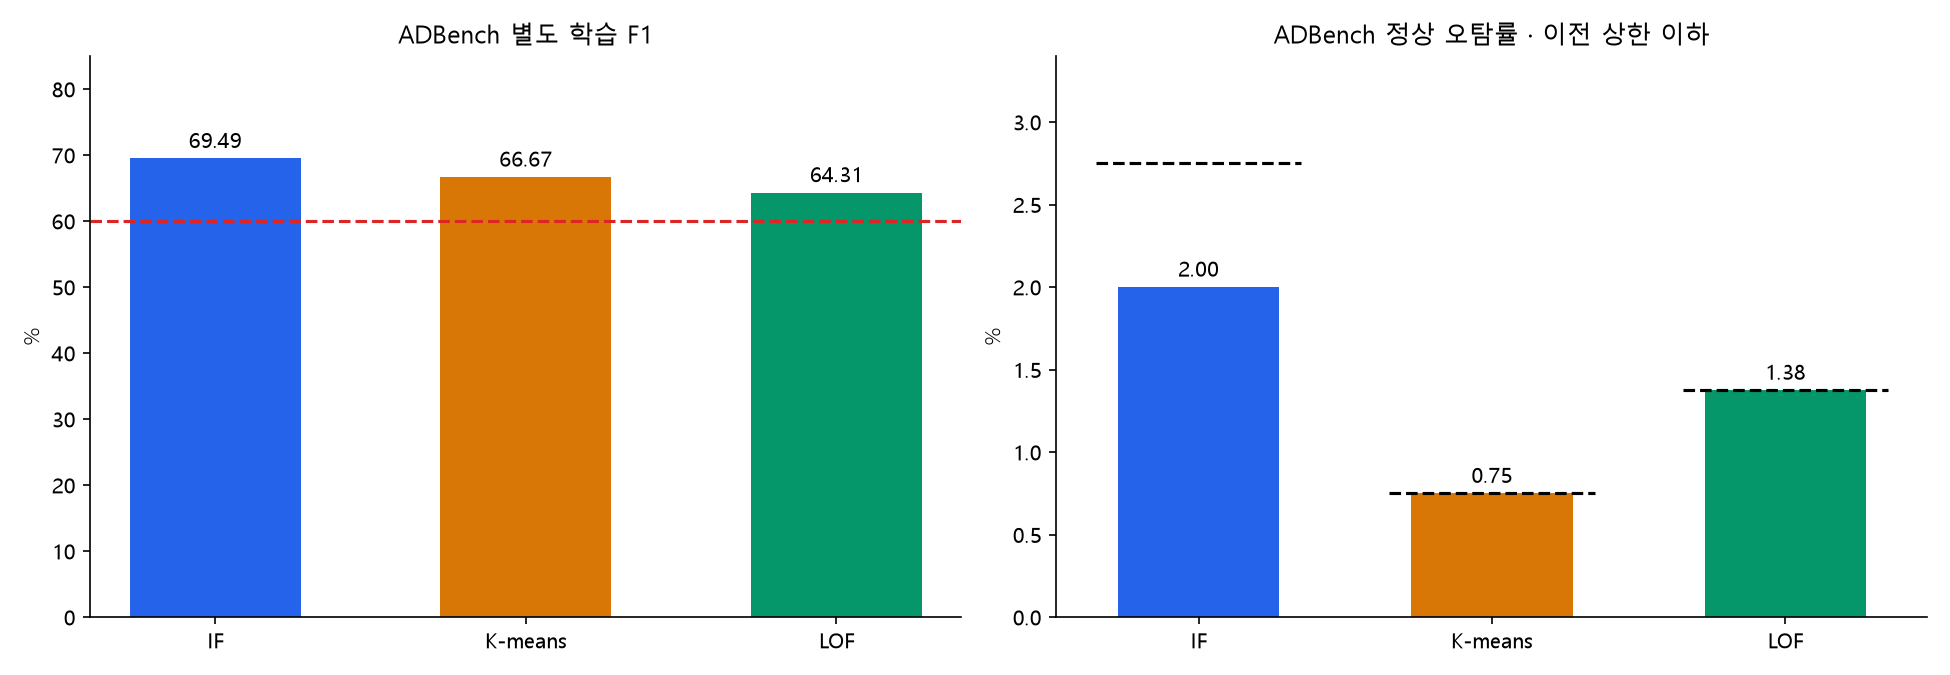

### if / ADBench 유형별

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
global,99.6,98.04,100.0,99.01,0.5
local,84.8,83.33,30.0,44.12,1.5
cluster,82.0,85.71,12.0,21.05,0.5
dependency,93.2,80.00,88.0,83.81,5.5


### kmeans / ADBench 유형별

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
global,99.6,98.04,100.0,99.01,0.5
local,82.4,87.50,14.0,24.14,0.5
cluster,80.8,75.00,6.0,11.11,0.5
dependency,96.0,93.48,86.0,89.58,1.5


### lof / ADBench 유형별

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
global,100.0,100.00,100.0,100.00,0.0
local,81.6,100.00,8.0,14.81,0.0
cluster,81.2,80.00,8.0,14.55,0.5
dependency,92.8,80.77,84.0,82.35,5.0


In [6]:
display(metrics(ad['results'])); display(pd.DataFrame(ad['results'])[['method','tp','fp','fn','tn','FP_cap','F1_target_met','FP_cap_met','threshold']])
display(Image(filename=str(LOG/'figures/adbench_specific.png')))
for r in ad['results']:
    display(Markdown('### '+r['method']+' / ADBench 유형별')); display(metrics([{'method':k,**v}for k,v in r['by_mode'].items()]))

## 6. 서비스 모델의 ADBench 무학습 전이: 미달

위 표는 ADBench용으로 다시 학습한 **다른 모델 파일**이다. 서비스 모델 그대로의 전이는 아래처럼 별도로 공개한다. 특히 K-means는 입력에 시계열 이력이 없어 정상까지 대량 경보하므로 이런 피처 표를 운영 Monitor에 넣으면 안 된다. **무학습 전이 F1 60% 목표는 달성하지 못했다.**

In [7]:
transfer=read(LOG/'adbench_transfer.json'); display(metrics(transfer['results'])); display(pd.DataFrame(transfer['results'])[['method','fp','FP_cap','F1_target_met','FP_cap_met']])

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,79.9,47.37,4.5,8.22,1.25
kmeans,20.0,20.00,100.0,33.33,100.00
lof,79.9,0.00,0.0,0.00,0.12


,method,fp,FP_cap,F1_target_met,FP_cap_met
0,if,10,22,False,True
1,kmeans,800,6,False,False
2,lof,1,11,False,True


## 7. 새 seed 확인과 저장 모델

최종 경보 정책 고정 후 새 seed **48600042**에서 추가 비교. 같은 원본 pool·원형 생성기이므로 외부 블라인드 검증은 아니며 기존 mild-v1 난이도와도 다르다. 이 결과로 모델을 다시 고르지 않았다.

운영 연결 후보는 `reports/shared_model_v4_final/handoff/*_shared.joblib`. ADBench 전용은 `reports/shared_model_v4_adbench_release/*_adbench_specific.joblib`이며 서로 대체 불가. 원시 로그 스트리밍의 상태 저장·빈 분 생성·지연 도착 처리는 worker에서 추가 구현해야 한다. 모델/데이터 의존 코드는 `code/` 필요, joblib는 신뢰하는 파일만 로드.

In [8]:
fresh=read(LOG/'fresh_comparison.json')
for version in ['previous','new']:
    display(Markdown('### 새 seed / '+version)); display(metrics([r for r in fresh['rows']if r['version']==version]))
audit=read(LOG/'audit.json'); display({k:audit[k]for k in ['checks_passed','goals_met','unchanged_fixed_benchmarks','unit_tests_run','unit_tests_passed']})
display(pd.DataFrame([{'모델':r['algorithm'],'파일':r['file'],'크기 bytes':r['bytes'],'raw Process 입력 확인':r['raw_Process_predict'],'과거 판정 불변':r['prefix_causal']}for r in manifest['models']]))

### 새 seed / previous

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,88.78,72.52,49.06,58.53,3.58
kmeans,90.03,83.61,47.50,60.58,1.79
lof,89.04,75.94,46.93,58.01,2.86


### 새 seed / new

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,91.56,86.91,56.12,68.20,1.63
kmeans,92.56,89.35,61.15,72.60,1.40
lof,92.46,93.27,57.38,71.05,0.80


{'checks_passed': True,
 'goals_met': {'if': True, 'kmeans': True, 'lof': True},
 'unchanged_fixed_benchmarks': True,
 'unit_tests_run': 62,
 'unit_tests_passed': True}

,모델,파일,크기 bytes,raw Process 입력 확인,과거 판정 불변
0,if,if_shared.joblib,2773707,True,True
1,kmeans,kmeans_shared.joblib,343338,True,True
2,lof,lof_shared.joblib,11656289,True,True


## 한계와 다음 평가

- 현재 성능은 같은 합성 평가셋을 반복 사용한 연구 결과. 숫자만 맞추었다고 운영 성능을 보증하지 않음. 외부 정상 로그와 숨겨둔 새 이상 사례로 최종 동결 후 재검증 필요.
- 개별 지연·관계 이상·폭주 등 유형별 회귀가 남음. 전체 F1만으로 서비스 후보를 최종 선정하지 말고 필수 장애 유형의 최소 Recall과 운영 허용 오탐량도 합의 필요.
- ADBench 전용 재학습과 서비스 무학습 전이를 혼동하면 안 됨. 유형별로 local/cluster가 여전히 어려우며 ADBench 유형도 ESB 장애 시나리오와 다름.
- 첫 관측의 오염, 새로운 시간대·주기, Adapter/Process 분포 변화, 완료되지 않는 장기 작업 및 빈 분 처리에 대한 운영 검증 필요.

참고: [ADBench 공식 생성기](https://github.com/Minqi824/ADBench/blob/main/adbench/datasets/data_generator.py), [ADBench 논문](https://arxiv.org/abs/2206.09426), [NIST CUSUM 설명](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm), [scikit-learn QuantileTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html). CUSUM 아이디어를 사용한 피처이며 NIST 관리도를 그대로 재현한 것은 아님.